In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import pandas as pd
df = pd.read_csv('hotel_bookings.csv')
print("Dataset loaded Successfully")

Dataset loaded Successfully


In [3]:
print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

In [4]:
print(df.shape)

(119390, 32)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
print(df.isnull().sum())

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

# Handle missing values:

In [7]:
df['children'] = df['children'].fillna(0)

df['country'] = df['country'].fillna('Unknown')

df['agent'] = df['agent'].fillna(0)

df['company'] = df['company'].fillna(0)

print(df.isnull().sum())

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

# Create lead time features

In [8]:
df['lead_time_category'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, 365, float('inf')],
    labels=['Last Minute', 'Short', 'Medium',
            'Long', 'Very Long']
)

print(df[['lead_time', 'lead_time_category']].head())

   lead_time lead_time_category
0        342               Long
1        737          Very Long
2          7        Last Minute
3         13              Short
4         14              Short


# Calculate total stay length

In [9]:
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

print(df[['stays_in_weekend_nights',
          'stays_in_week_nights',
          'total_nights']].head())

   stays_in_weekend_nights  stays_in_week_nights  total_nights
0                        0                     0             0
1                        0                     0             0
2                        0                     1             1
3                        0                     1             1
4                        0                     2             2


# Handle cancellation flags

In [10]:
df['cancellation_status'] = df['is_canceled'].map({
    0: 'Not Canceled',
    1: 'Canceled'
})

print(df['cancellation_status'].value_counts())

cancellation_status
Not Canceled    75166
Canceled        44224
Name: count, dtype: int64


# Customer segment profiling

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64


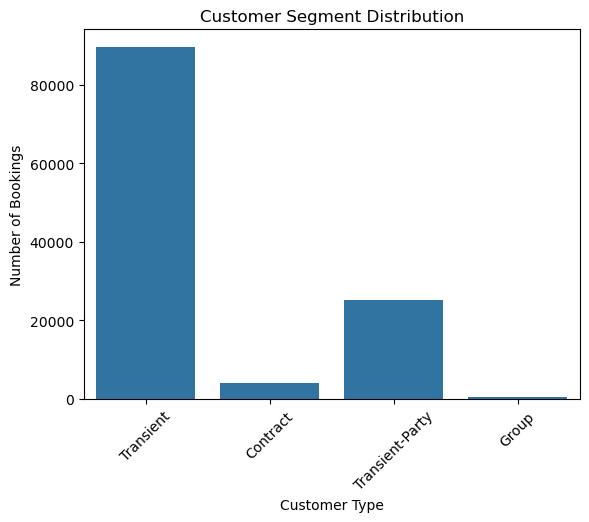

In [12]:
print(df['customer_type'].value_counts())

sns.countplot(data=df, x='customer_type')

plt.title('Customer Segment Distribution')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.show()

# Final cleaned dataset

In [13]:
print(df.head())

print("Rows and Columns:", df.shape)

print("Missing Values:")
print(df.isnull().sum())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  \
0                        0                     0       2  ...   
1                        0        

In [15]:
df.to_csv('cleaned_hotel_bookings.csv', index=False)

# Hotel Booking Demand – Revenue Management & Seasonality Analytics

# Resort Hotel vs City Hotel trends

In [16]:
hotel_trends = df.groupby('hotel').agg(
    Total_Bookings=('hotel', 'count'),
    Average_ADR=('adr', 'mean'),
    Average_Lead_Time=('lead_time', 'mean'),
    Average_Stay=('total_nights', 'mean')
)

print(hotel_trends)

              Total_Bookings  Average_ADR  Average_Lead_Time  Average_Stay
hotel                                                                     
City Hotel             79330   105.304465         109.735724      2.978142
Resort Hotel           40060    94.952930          92.675686      4.318547


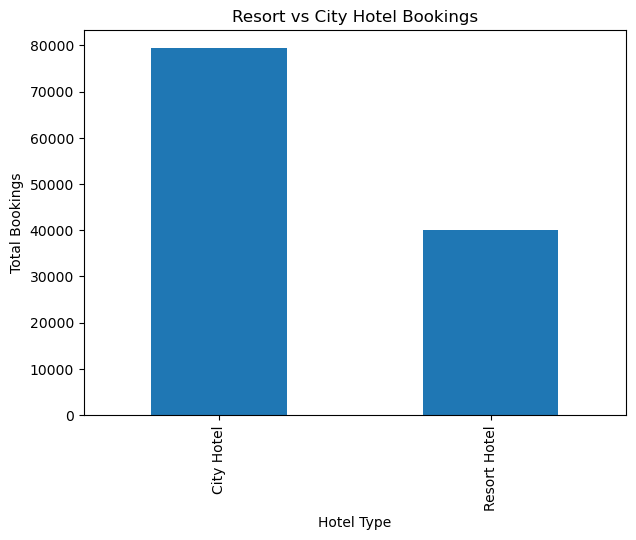

In [17]:
hotel_trends['Total_Bookings'].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Resort vs City Hotel Bookings')
plt.xlabel('Hotel Type')
plt.ylabel('Total Bookings')
plt.show()

# Cancellation vs Lead Time relationship

In [18]:
cancellation_data = df.groupby('is_canceled')['lead_time'].mean()

print(cancellation_data)

is_canceled
0     79.984687
1    144.848815
Name: lead_time, dtype: float64


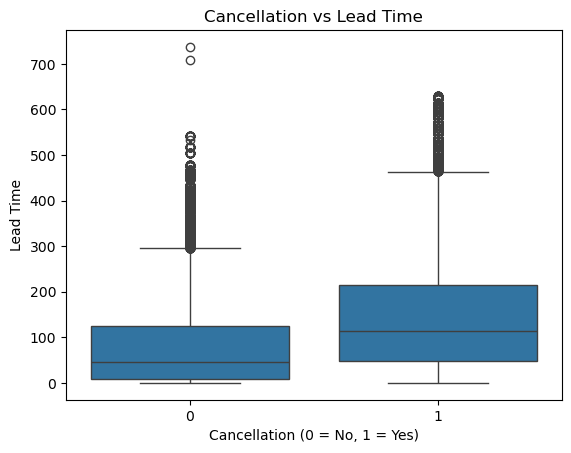

In [19]:
sns.boxplot(
    data=df,
    x='is_canceled',
    y='lead_time'
)

plt.title('Cancellation vs Lead Time')
plt.xlabel('Cancellation (0 = No, 1 = Yes)')
plt.ylabel('Lead Time')
plt.show()

# Monthly seasonal booking analysis

In [20]:
monthly_bookings = df.groupby(
    'arrival_date_month',
    sort=False
)['hotel'].count()

print(monthly_bookings)

arrival_date_month
July         12661
August       13877
September    10508
October      11160
November      6794
December      6780
January       5929
February      8068
March         9794
April        11089
May          11791
June         10939
Name: hotel, dtype: int64


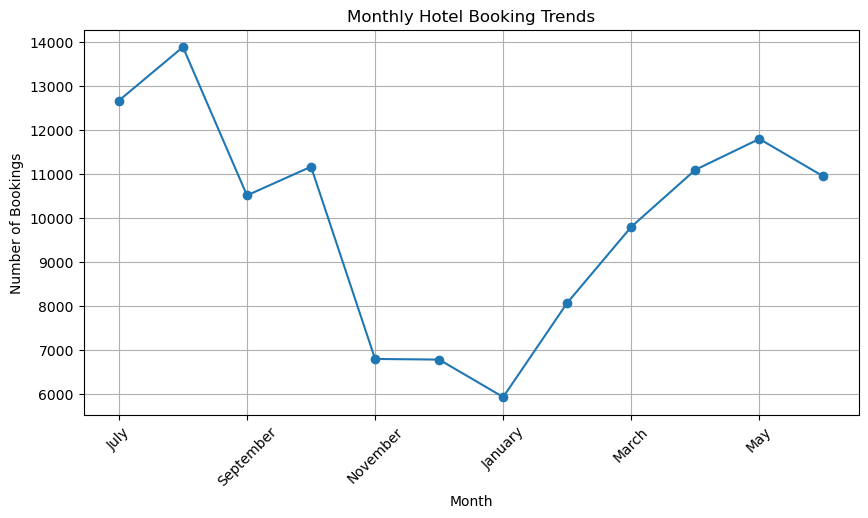

In [21]:
monthly_bookings.plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.title('Monthly Hotel Booking Trends')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.grid()
plt.show()

# ADR pricing strategy analysis

In [22]:
adr_analysis = df.groupby('hotel')['adr'].mean()

print(adr_analysis)

hotel
City Hotel      105.304465
Resort Hotel     94.952930
Name: adr, dtype: float64


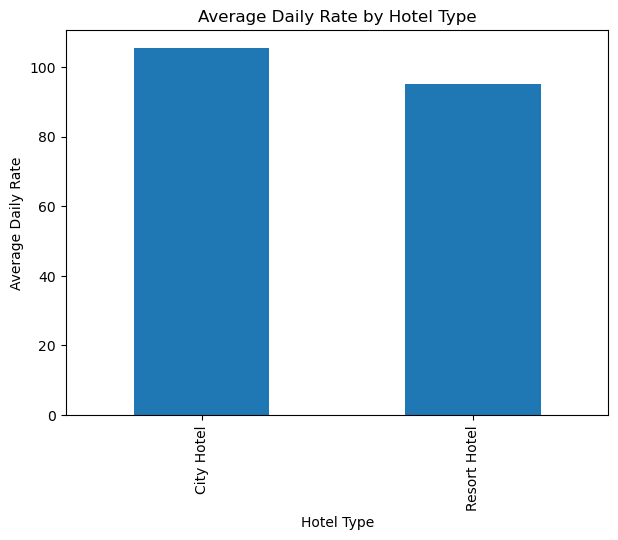

In [23]:
adr_analysis.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Average Daily Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate')
plt.show()

# Cancellation rate by hotel type

In [25]:
cancellation_rate = df.groupby('hotel')['is_canceled'].mean() * 100

print(cancellation_rate) 

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


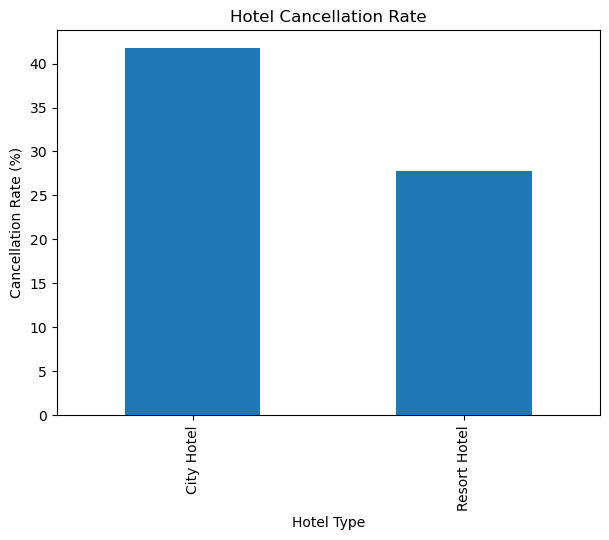

In [26]:
cancellation_rate.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Hotel Cancellation Rate')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.show()

# Final revenue analysis

In [27]:
df['estimated_revenue'] = (
    df['adr'] * df['total_nights']
)

revenue = df[df['is_canceled'] == 0].groupby(
    'hotel'
)['estimated_revenue'].sum()

print("Estimated Revenue:")
print(revenue)

Estimated Revenue:
hotel
City Hotel      14394410.18
Resort Hotel    11601850.23
Name: estimated_revenue, dtype: float64


# HOTEL BOOKING DEMAND ANALYSIS

## 1. Introduction
Hotel Booking Demand Analysis is used to study hotel reservations, customer behaviour, cancellations and revenue trends using Python.

## 2. Objectives
- To clean the hotel booking dataset.
- To handle missing and duplicate values.
- To analyse lead time and stay duration.
- To compare City and Resort Hotels.
- To study cancellations and seasonal trends.
- To analyse hotel pricing using ADR.

## 3. Dataset Description
The dataset contains 119,390 records and 32 columns. It includes hotel type, lead time, arrival date, customer type, cancellation status and ADR.

## 4. Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 5. Topic 13 – Data Cleaning
- Checked and handled missing values.
- Removed duplicate records.
- Created lead time categories.
- Calculated total stay nights.
- Created cancellation status.
- Analysed customer segments.

## 6. Topic 14 – Revenue Management & Seasonality Analytics
- Compared City Hotels and Resort Hotels.
- Analysed cancellation and lead time relationships.
- Studied monthly booking trends.
- Compared Average Daily Rate (ADR).
- Calculated cancellation rates.
- Estimated hotel room revenue.

## 7. Results
- City Hotels received more bookings.
- Resort Hotels had longer average stays.
- City Hotels had higher cancellation rates.
- Canceled bookings had higher average lead time.
- August recorded the highest booking demand.
- City Hotels had higher average ADR.

## 8. Conclusion
The project successfully analysed hotel booking data using Python. Data cleaning, feature engineering and visualisation helped identify customer behaviour, cancellation patterns, seasonal demand and pricing trends. This analysis supports better hotel management and business decisions.

## 9. References
1. Kaggle – Hotel Booking Demand Dataset.
2. Python Documentation.
3. Pandas Documentation.
4. Matplotlib Documentation.